# Trabajo Final Integrador
## Comienzo


In [1]:
import pandas as pd
import numpy as np
pd.__version__

'2.2.3'

# Punto 1 - Elección y justificación del dataset

Seleccione de Kaggle el siguiente dataset:


https://www.kaggle.com/datasets/kukuroo3/body-performance-data


Soy profesor de educación física y mi idea es lograr llevar el análisis de datos hacia ese rubro. Entre varios dataset que había pre-seleccionado este me pareció uno de los más completos que sí cumplían con los requisitos mínimos. Me interesó porque tiene información variada que va desde resultados de pruebas físicas deportivas hasta resultados de pruebas de salud. Sin dudas a futuro me gustaría poder profundizar en esta temática.


**Mi pregunta principal es:** ¿Qué variables diferencian mejor a las personas de alto y bajo rendimiento físico (clase A vs. D), y cómo cambia según edad y sexo?


# Punto 2 - Dataset de Performance Corporal



## 2.1 Carga de Dataset






In [2]:
# Cargo el csv elegido desde Google Drive y lo renombro como df_perf

df = pd.read_csv("/content/drive/MyDrive/bodyPerformance.csv")
df_perf = pd.read_csv("/content/drive/MyDrive/bodyPerformance.csv")
df_perf

,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B
...,...,...,...,...,...,...,...,...,...,...,...,...
13388,25.0,M,172.1,71.80,16.2,74.0,141.0,35.8,17.4,47.0,198.0,C
13389,21.0,M,179.7,63.90,12.1,74.0,128.0,33.0,1.1,48.0,167.0,D
13390,39.0,M,177.2,80.50,20.1,78.0,132.0,63.5,16.4,45.0,229.0,A
13391,64.0,F,146.1,57.70,40.4,68.0,121.0,19.3,9.2,0.0,75.0,D


## 2.2 Exploración Estructural

In [3]:
# Comienzo con el análisis de la estructura del mismo
# ¿Cuántas filas y columnas tiene?

df_perf.shape

(13393, 12)

In [4]:
#Panorama general: Columnas, nulos y tipos

df_perf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13393 entries, 0 to 13392
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      13393 non-null  float64
 1   gender                   13393 non-null  object 
 2   height_cm                13393 non-null  float64
 3   weight_kg                13393 non-null  float64
 4   body fat_%               13393 non-null  float64
 5   diastolic                13393 non-null  float64
 6   systolic                 13393 non-null  float64
 7   gripForce                13393 non-null  float64
 8   sit and bend forward_cm  13393 non-null  float64
 9   sit-ups counts           13393 non-null  float64
 10  broad jump_cm            13393 non-null  float64
 11  class                    13393 non-null  object 
dtypes: float64(10), object(2)
memory usage: 1.2+ MB


**Lectura del info():**

*   No hay nulos en ninguna de las categorias.
*   Son 13393 filas y 12 columnas
*   Gender y Class son object, lo cuál es correcto y no es necesario cambiar el tipo.


In [5]:
# Corroboramos los tipos de archivo

df_perf.dtypes

,0
age,float64
gender,object
height_cm,float64
weight_kg,float64
body fat_%,float64
diastolic,float64
systolic,float64
gripForce,float64
sit and bend forward_cm,float64
sit-ups counts,float64


##   2.3 Exploración Estadistica Inicial

In [6]:
# Estadisticas de las columnas numéricas

df_perf.describe()

,age,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm
count,13393.000000,13393.000000,13393.000000,13393.000000,13393.000000,13393.000000,13393.000000,13393.000000,13393.000000,13393.000000
mean,36.775106,168.559807,67.447316,23.240165,78.796842,130.234817,36.963877,15.209268,39.771224,190.129627
std,13.625639,8.426583,11.949666,7.256844,10.742033,14.713954,10.624864,8.456677,14.276698,39.868000
min,21.000000,125.000000,26.300000,3.000000,0.000000,0.000000,0.000000,-25.000000,0.000000,0.000000
25%,25.000000,162.400000,58.200000,18.000000,71.000000,120.000000,27.500000,10.900000,30.000000,162.000000
50%,32.000000,169.200000,67.400000,22.800000,79.000000,130.000000,37.900000,16.200000,41.000000,193.000000
75%,48.000000,174.800000,75.300000,28.000000,86.000000,141.000000,45.200000,20.700000,50.000000,221.000000
max,64.000000,193.800000,138.100000,78.400000,156.200000,201.000000,70.500000,213.000000,80.000000,303.000000


***Observación*** Los mínimos de las columnas diastolic, systolic, gripforce y broad jump_cm no pueden ser 0, lo que es sospechoso.


Tanto el mínimo como el máximo de sit and bend son sospechosos, ya que el valor negativo es muy extremo y el máximo es imposible.


Los extremos de body fat_% son poco creíbles, tanto el mínimo como el máximo.

Es probable que sean datos que erroneamente tienen 0 o que sean errores de medición, y esto hay que tenerlo en cuenta a la hora de hacer un análisis.

##  2.4 Limpieza

### A) Duplicados: Identificación y eliminación por criterio

In [7]:
df.duplicated().sum()

np.int64(1)

In [8]:
df_perf[df_perf.duplicated(keep=False)]

,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
8965,27.0,F,157.0,49.1,30.7,70.0,86.0,27.7,19.7,51.0,167.0,A
12473,27.0,F,157.0,49.1,30.7,70.0,86.0,27.7,19.7,51.0,167.0,A


In [9]:
# Es improbable que en tantas personas y tantas mediciones/pruebas distintas alguien tenga exactamente los mismo resultados en todo, por lo tanto decido eliminar el duplicado

df_perf = df_perf.drop_duplicates()
df_perf.shape

(13392, 12)

### B) Valores nulos y criterio de tratamiento

In [10]:
# Reviso si hay nulos en mi dataset

df_perf.isnull().sum()

,0
age,0
gender,0
height_cm,0
weight_kg,0
body fat_%,0
diastolic,0
systolic,0
gripForce,0
sit and bend forward_cm,0
sit-ups counts,0


No hay nulos explícitos, pero procedo a revisar los casos sospechosos que observé previamente.

In [11]:
# Realizo un conteo de los casos sospechosos de las columnas:

print("diastolic = 0:", (df["diastolic"] == 0).sum())
print("systolic = 0:", (df["systolic"] == 0).sum())
print("gripForce = 0:", (df["gripForce"] == 0).sum())
print("broad jump = 0:", (df["broad jump_cm"] == 0).sum())
print("sit and bend > 70:", (df["sit and bend forward_cm"] > 70).sum())
print("sit and bend < -10:", (df["sit and bend forward_cm"] < -10).sum())
print("diastolic > 120:", (df["diastolic"] > 120).sum())

diastolic = 0: 1
systolic = 0: 1
gripForce = 0: 3
broad jump = 0: 10
sit and bend > 70: 2
sit and bend < -10: 132
diastolic > 120: 3


In [12]:
# Chequeo si en alguna fila la presión diastólica es igual o mayor que la sistólica, ya que eso es imposible fisiológicamente.
(df["diastolic"] >= df["systolic"]).sum()

np.int64(5)

CRITERIO DE DECISIÓN PARA CADA CASO PLANTEADO PREVIAMENTE:





**Caso:** diastolic = 0 / systolic = 0        **Decisión:** Eliminar: presión imposible


**Caso**: diastolic > 120    **Decisión:** Eliminar: valor extremo, probable error

**Caso**: diastolic ≥ systolic **Decisión:** Eliminar: fisiológicamente imposible

**Caso**: gripForce = 0 **Decisión:** Eliminar: medición no registrada

**Caso**: broad jump = 0 **Decisión:** Eliminar: medición no registrada

**Caso**: sit and bend > 70 **Decisión:** Eliminar: fuera de la escala del test

**Caso:** sit and bend < -10 **Decisión:** Conservar: negativo es válido (no llega a la punta de los pies)

In [13]:
# Convierto a nulos los casos correspondientes
# Ceros imposibles
cols_cero = ["diastolic", "systolic", "gripForce", "broad jump_cm"]
df_perf[cols_cero] = df_perf[cols_cero].replace(0, np.nan)

# Valores fuera de rango fisiológico
df_perf.loc[df_perf["diastolic"] > 120, "diastolic"] = np.nan
df_perf.loc[df_perf["sit and bend forward_cm"] > 70, "sit and bend forward_cm"] = np.nan

# Diastólica mayor o igual a la sistólica
df_perf.loc[df_perf["diastolic"] >= df_perf["systolic"], ["diastolic", "systolic"]] = np.nan

df_perf.isnull().sum()

/tmp/ipykernel_544/921191889.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_perf[cols_cero] = df_perf[cols_cero].replace(0, np.nan)


,0
age,0
gender,0
height_cm,0
weight_kg,0
body fat_%,0
diastolic,7
systolic,4
gripForce,3
sit and bend forward_cm,2
sit-ups counts,0


In [14]:
# Procedo a eliminar según corresponde
filas_antes = df_perf.shape[0]
df_perf = df_perf.dropna()
print("Filas eliminadas:", filas_antes - df_perf.shape[0])
print("Filas restantes:", df_perf.shape[0])

Filas eliminadas: 22
Filas restantes: 13370


In [15]:
# Compruebo que haya quedado limpio
df_perf.isnull().sum()
(df_perf["diastolic"] >= df_perf["systolic"]).sum()

np.int64(0)

### C) Corrección de tipos

In [16]:
# Prefiero que la columna age quede como número entero ya que me parece más útil y no es significativo de la otra manera.

df_perf["age"] = df_perf["age"].astype(int)
df_perf.dtypes

,0
age,int64
gender,object
height_cm,float64
weight_kg,float64
body fat_%,float64
diastolic,float64
systolic,float64
gripForce,float64
sit and bend forward_cm,float64
sit-ups counts,float64


In [17]:
# Solo debe haber A/B/C/D en la columna de "class" por lo tanto procedo a corroborarlo.

df_perf["class"].value_counts()

,count
class,
B,3344
C,3343
A,3343
D,3340


In [18]:
# Solo debe haber M/F en la columna de "gender" por lo tanto procedo a corroborarlo.
df_perf["gender"].value_counts()

,count
gender,
M,8455
F,4915


13.393 filas originales → 13.370 tras la limpieza (−0,17 %).

Los números coinciden con lo mostrado, por lo tanto se corrobora que las columnas de "class" y "gender" están limpias. También se observa que hay más varones que mujeres y eso puede ser relevante para ciertos tipos de comparaciones.

### D) Estandarización de nombres

Elimino signos incómodos, elimino espacios en blanco y reemplazamos con "_" y también paso todo a letras minúscula.

In [19]:
df_perf = df_perf.rename(columns={
    "body fat_%": "body_fat_pct",
    "gripForce": "gripforce",
    "sit and bend forward_cm": "sit_and_bend_forward_cm",
    "sit-ups counts": "sit_ups_counts",
    "broad jump_cm": "broad_jump_cm"
})

In [20]:
#Chequeo que los cambios se hayan realizado correctamente

df_perf.columns.tolist()

['age',
 'gender',
 'height_cm',
 'weight_kg',
 'body_fat_pct',
 'diastolic',
 'systolic',
 'gripforce',
 'sit_and_bend_forward_cm',
 'sit_ups_counts',
 'broad_jump_cm',
 'class']

# Punto 3 - Exploración y visualización

In [21]:
# Comienzo importando matplotlib y seaborn

import matplotlib.pyplot as plt
import seaborn as sns


## 3.1 Abdominales por clase de rendimiento y sexo

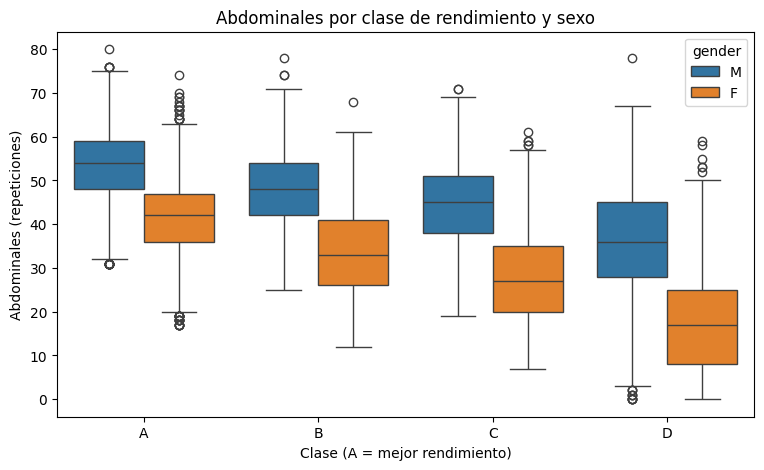

In [22]:
# Primero quiero saber si el resultado de las pruebas va a reflejar correctamente la categoría a la que la persona fue asociada.
# Para eso, tomo la prueba de abdominales y la separo por sexo ya que eso tiene impacto directo en el rendimiento de la prueba.

plt.figure(figsize=(9, 5))
sns.boxplot(data=df_perf, x="class", y="sit_ups_counts", hue="gender",
            order=["A", "B", "C", "D"])
plt.title("Abdominales por clase de rendimiento y sexo")
plt.xlabel("Clase (A = mejor rendimiento)")
plt.ylabel("Abdominales (repeticiones)")
plt.show()

Como conclusión del primer grafico, los abdominales disminuyen correctamente de la clase A a la D en ambos sexos, y los hombres superan a las mujeres en todas las clases en prueba de abdominales. Por lo tanto, la prueba discrimina bien entre niveles de rendimiento.

Por otro lado, si bien hay outliers presentes, están dentro de valores posibles.

## 3.2 Correlaciones entre variables y rendimiento (class_num)

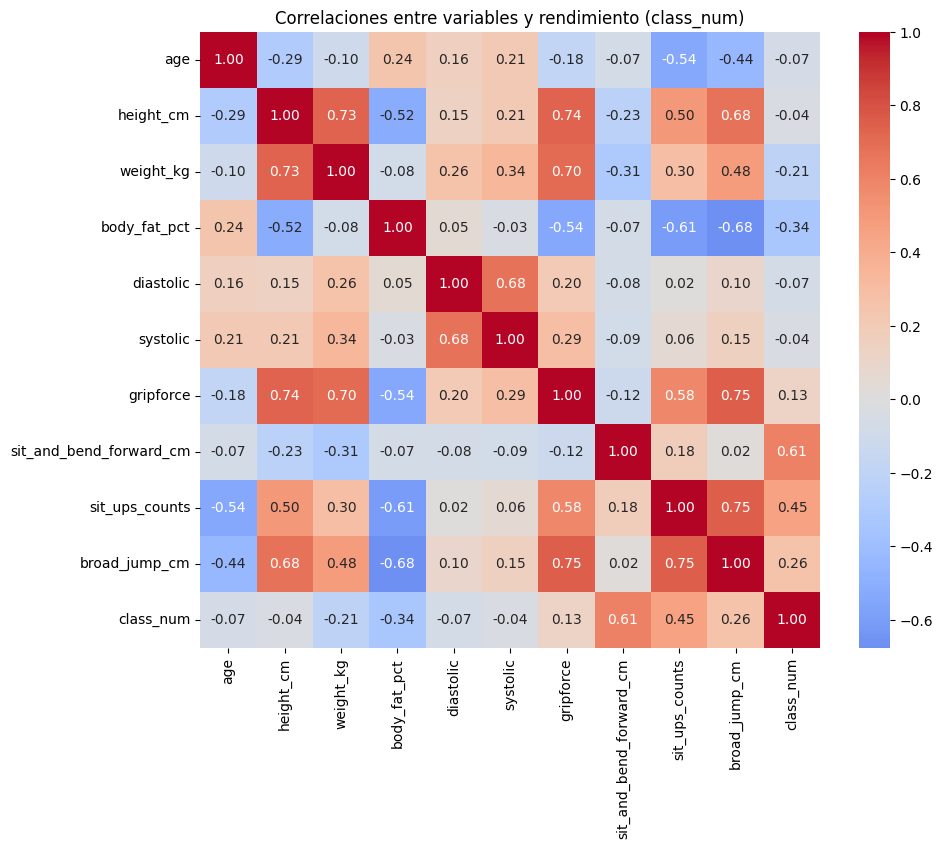

In [23]:
# A continuación, asociado con mi pregunta principal, busco saber cuales son las variables más relacionadas con el rendimiento.

# Para eso, realizo un heatmap y genero una columna derivada: clase en formato numérico (A = 4 ... D = 1) para poder realizar el gráfico.


df_perf["class_num"] = df_perf["class"].map({"A": 4, "B": 3, "C": 2, "D": 1})

corr = df_perf.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlaciones entre variables y rendimiento (class_num)")
plt.show()

Como conclusión de este gráfico, la flexibilidad (r = 0,61) y los abdominales (r = 0,45) son las variables más asociadas a la clase. Entre las medidas corporales, el % de grasa es la más relevante (r = -0,34). La edad, la altura y la presión arterial casi no se relacionan con la clase.

## 3.3 Correlación de cada variable con la clase, por sexo

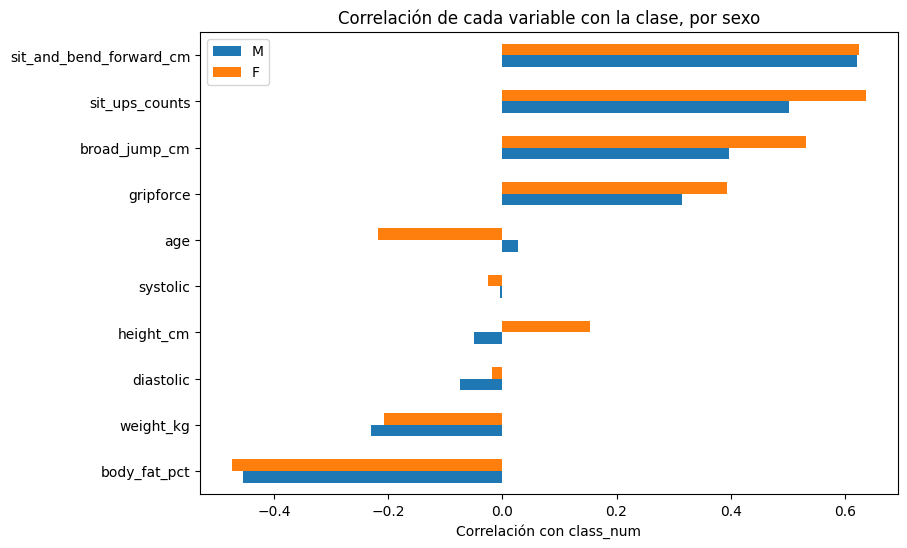

In [24]:
# Ahora lo que quiero es distinguir la asociación de cada prueba con el rendimiento pero separado por sexo, ya que es parte de mi pregunta principal

num_cols = ["age", "height_cm", "weight_kg", "body_fat_pct", "diastolic", "systolic",
            "gripforce", "sit_and_bend_forward_cm", "sit_ups_counts", "broad_jump_cm"]

corr_sexo = pd.DataFrame({
    g: df_perf[df_perf["gender"] == g][num_cols].corrwith(df_perf[df_perf["gender"] == g]["class_num"])
    for g in ["M", "F"]
})

corr_sexo.sort_values("M").plot(kind="barh", figsize=(9, 6))
plt.title("Correlación de cada variable con la clase, por sexo")
plt.xlabel("Correlación con class_num")
plt.show()

Como conclusión, al separar por sexo las cuatro pruebas físicas se asocian fuertemente con la clase de rendimiento, destacando la flexibilidad y los abdominales (r ≈ 0,5–0,67). Se confirma que el % de grasa es la medida corporal más relevante (r ≈ -0,46 a -0,49). La altura y la presión arterial prácticamente no se relacionan con la clase. La relación entre las pruebas y la clase es algo más fuerte en mujeres que en hombres.

## 3.4 Porcentaje de personas en clase A por grupo de edad y sexo

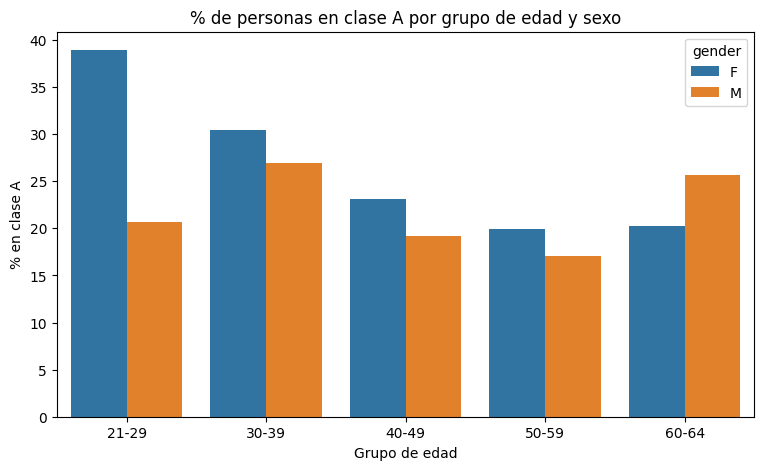

In [25]:
# Por último, para responder a la otra parte de mi pregunta principal, quiero saber si está asociada la edad al grupo de rendimiento asignado.

# Para eso genero una columna derivada: grupo de edad, que me muestre de manera diferenciada esa relación.

df_perf["age_group"] = pd.cut(df_perf["age"], bins=[20, 29, 39, 49, 59, 64],
                              labels=["21-29", "30-39", "40-49", "50-59", "60-64"])

pct_a = (df_perf.groupby(["age_group", "gender"], observed=True)["class"]
         .apply(lambda s: (s == "A").mean() * 100)
         .reset_index(name="pct_clase_A"))

plt.figure(figsize=(9, 5))
sns.barplot(data=pct_a, x="age_group", y="pct_clase_A", hue="gender")
plt.title("% de personas en clase A por grupo de edad y sexo")
plt.xlabel("Grupo de edad")
plt.ylabel("% en clase A")
plt.show()

In [26]:
# Luego de lo observado, me parece importante saber a cuántos casos corresponde cada una de las segmentaciones por edad.

df_perf.groupby(["age_group", "gender"], observed=True).size()

age_group  gender
21-29      F         2130
           M         3654
30-39      F          716
           M         1942
40-49      F          693
           M         1170
50-59      F          843
           M          895
60-64      F          533
           M          794
dtype: int64

Como resultado de este gráfico, se observa que en las mujeres el porcentaje de personas en clase A disminuye con la edad (de ~39 % entre 21 y 29 años a ~20 % desde los 50). En los hombres no se observa una tendencia clara. Esto indica que la edad se asocia con el rendimiento sobre todo en mujeres, al menos en esta muestra obtenida. Todos los grupos tienen al menos 533 personas, por lo que las diferencias observadas no se deben a muestras pequeñas. Sin embargo, la muestra está concentrada en el grupo de 21 a 29 años , por lo que los resultados representan mejor a población joven.

# Conclusión final

Pregunta: ¿Qué variables diferencian mejor a las personas de alto y bajo rendimiento físico (clase A vs. D), y cómo cambia según edad y sexo?

1 - Las pruebas físicas son las variables que mejor diferencian la clase de rendimiento. La flexibilidad (r ≈ 0,66) y los abdominales (r ≈ 0,53 en hombres y 0,67 en mujeres) son las más asociadas, seguidas por el salto en largo y la fuerza de agarre.


2 - Entre las medidas corporales, el % de grasa es la más relevante (r ≈ -0,46 a -0,49): más grasa corporal se asocia con una peor clase. El peso tiene una relación leve y la altura y la presión arterial casi no se relacionan con la clase.


3 - Separar por sexo fue clave. En el análisis general, la fuerza de agarre (r = 0,13) y el salto (r = 0,26) parecían poco relevantes, pero dentro de cada sexo la asociación es mucho mayor (r ≈ 0,33–0,56). En general, las pruebas se asocian más con la clase en mujeres que en hombres.


4 - La edad afecta de forma distinta a cada sexo. En mujeres, el % de personas en clase A baja de ~39 % (21-29 años) a ~20 % (desde los 50). En hombres no hay una tendencia clara.

Todo esto es en base a la muestra sobre la cuál se trabajo y no quiere decir que sea representativo de una población mucho mayor.

In [27]:
# Guardo el csv limpio para poder trabajar con él.

df_perf.to_csv("bodyPerformance_limpio.csv", index=False)